# A flight's data and results with pils

Loads everything recorded for one flight, puts it on one clock, and reads the
analysis results stored with it -- nothing is re-processed.

| | Call | Result in |
|---|---|---|
| Drone | `flight.add_drone_data()` | `flight.raw_data.drone_data.drone` / `.litchi` |
| Camera | `flight.add_camera_data(use_photogrammetry=False)` | `flight.raw_data.payload_data.camera_obj` |
| Payload sensors | `flight.add_sensor_data(["gps", "imu", "inclinometer"])` | `flight.raw_data.payload_data.<sensor>` |
| Sync | `flight.sync()` | `flight.sync_data`, `flight.sync_offsets` |
| Photogrammetry | `PhotogrammetryAnalysis(flight).get_latest_version()` | `<flight>/proc/photogrammetry/` |
| EKF | `EKFAnalysis(flight).get_latest_version()` | `<flight>/proc/ekf/` |

Photogrammetry results are produced in IPA_flight (`IPA_flight/examples/`).

In [1]:
import sys
sys.path.insert(0, "/Users/federico/Desktop/ARS/pils")  # pils = ARS/pils/pils
sys.path.insert(0, "/Users/federico/Desktop/ARS")       # IPA_flight (used by PhotogrammetryAnalysis)

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

from pils.loader.path import PathLoader
from pils.flight import Flight
from pils.analyze import EKFAnalysis, PhotogrammetryAnalysis

DATA_ROOT = "/Volumes/WD/data/POLOCALC/"
FLIGHT_NAME = "flight_20261027_1318"

## Flight

`PathLoader` only resolves the folders; data is read by the `add_*` calls.

In [2]:
flight = Flight(PathLoader(DATA_ROOT).load_single_flight(flight_name=FLIGHT_NAME))
flight.flight_path

2026-11-03 12:15:21,931 - pils.loader.path - INFO - Loading single flight: flight_id=None, flight_name=flight_20261027_1318
2026-11-03 12:15:21,932 - pils.loader.path - INFO - Loading all flights from all campaigns...
2026-11-03 12:15:21,949 - pils.loader.path - WARNING - Could not build flight dict for proc /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/proc: time data '' does not match format '%Y%m%d_%H%M'
2026-11-03 12:15:21,950 - pils.loader.path - WARNING - Could not build flight dict for litchi_equivalent /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/litchi_equivalent: time data 'equivalent' does not match format '%Y%m%d_%H%M'
2026-11-03 12:15:21,950 - pils.loader.path - WARNING - Could not build flight dict for drone_equivalent /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/drone_equivalent: time data 'quivalent' does not match format '%Y%m%d_%H%M'
2026-11-03 12:15:21,951 - pils.loader.path - INFO - Loaded 11 flights from filesystem


PosixPath('/Volumes/WD/data/POLOCALC/campaigns/202610/20261027/flight_20261027_1318')

## Drone

DJI `.DAT` (+ Litchi log) when available; for the Matrice 400 the PSDK telemetry
`aux/uav_telemetry.bin`. Same columns either way: `timestamp`, `datetime`,
`RTK:lat_p/lon_p/hmsl_p`, `GPS:*` (+ `roll/pitch/yaw`, `isflying` from the telemetry).

In [3]:
flight.add_drone_data()
drone = flight.raw_data.drone_data.drone
litchi = flight.raw_data.drone_data.litchi
print(f"drone:  {drone.height} rows, {drone['datetime'].min()} -> {drone['datetime'].max()}")
print(f"litchi: {litchi.height} rows")
drone.select([c for c in ["datetime", "RTK:lat_p", "RTK:lon_p", "RTK:hmsl_p", "roll", "pitch", "yaw", "isflying"] if c in drone.columns]).head()

2026-11-03 12:15:21,975 - pils.flight - INFO - No drone .DAT/.csv in /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/flight_20261027_1318/drone -- using /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/flight_20261027_1318/aux/uav_telemetry.bin
2026-11-03 12:15:22,036 - pils.drones.DJIPSDKTelemetry - INFO - PSDK telemetry /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/flight_20261027_1318/aux/uav_telemetry.bin: 1114 rows on rtk_position, topics ['altitude_fused', 'flight_status', 'gps_details', 'gps_position', 'height_fusion', 'position_fused', 'quaternion', 'rtk_position', 'rtk_position_info', 'rtk_yaw', 'velocity'], 2026-10-27 12:19:01.974380 -> 2026-10-27 12:22:45.488150 UTC


drone:  1114 rows, 2026-10-27 12:19:01.974380 -> 2026-10-27 12:22:45.488150
litchi: 0 rows


datetime,RTK:lat_p,RTK:lon_p,RTK:hmsl_p,roll,pitch,yaw,isflying
datetime[μs],f64,f64,f64,f64,f64,f64,bool
2026-10-27 12:19:01.974380,45.61624,9.167353,236.375366,0.365608,0.932799,175.651139,false
2026-10-27 12:19:02.175248,45.61624,9.167353,236.375351,0.361151,0.932603,175.646815,false
2026-10-27 12:19:02.376966,45.61624,9.167353,236.384125,0.361872,0.928104,175.646792,false
2026-10-27 12:19:02.577102,45.61624,9.167353,236.382828,0.359818,0.930198,175.640637,false
2026-10-27 12:19:02.776909,45.61624,9.167353,236.382553,0.361941,0.931838,175.649587,false


## Camera

Alvium image sequence (`proc/images/frame_*.png` + `frame_timestamps.log`) or Sony video.
`camera.data[0]` has one row per frame (`timestamp`, `frame_num` for the Alvium).

2026-11-03 12:15:22,178 - pils.sensors.camera - INFO - Alvium tstart: 2026-10-27 12:19:02.550233


alvium: tstart=2026-10-27 12:19:02.550233 UTC, fps=5.00, 1116 logged frames, 1116 images


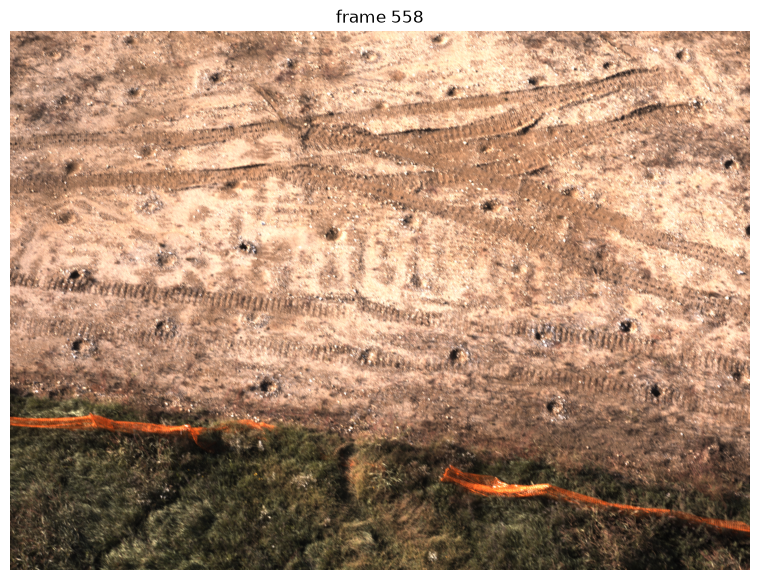

In [4]:
flight.add_camera_data(use_photogrammetry=False)
camera = flight.raw_data.payload_data.camera_obj
frames, model = camera.data
print(f"{model}: tstart={camera.tstart} UTC, fps={camera.fps:.2f}, {frames.height} logged frames, {len(camera.images)} images")

frame_number = frames.height // 2
plt.figure(figsize=(10, 7))
plt.imshow(camera.get_frame(frame_number)[:, :, ::-1])  # BGR -> RGB
plt.title(f"frame {frame_number}"); plt.axis("off"); plt.show()

## Payload sensors

- `gps`: ZED-F9P (UBX), the reference clock of the sync
- `imu`: payload IMU, `.accelerometer/.gyroscope/.magnetometer/.barometer` (`.data`, timestamp in µs)
- `inclinometer`: IMX5, `["INS"]` attitude (deg), `["IMU"]`, `["INL2"]`

In [5]:
flight.add_sensor_data(["gps", "imu", "inclinometer"])
payload = flight.raw_data.payload_data

gps = payload.gps
imu = payload.imu
ins = payload.inclinometer["INS"]
for name, df in [("gps", gps), ("imu accelerometer", imu.accelerometer.data), ("IMX5 INS", ins)]:
    print(f"{name:18s} {df.height:7d} rows, {df['datetime'].min()} -> {df['datetime'].max()}")

2026-11-03 12:15:23,587 - pils.sensors.inclinometer - INFO - Inclinometer sensor type: imx5


gps                    451 rows, 2026-10-27 12:19:00 -> 2026-10-27 12:22:45
imu accelerometer    34380 rows, 2026-10-27 12:18:56.064892 -> 2026-10-27 12:22:45.256949
IMX5 INS             32796 rows, 2026-10-27 12:18:56.058299 -> 2026-10-27 12:22:45.620176


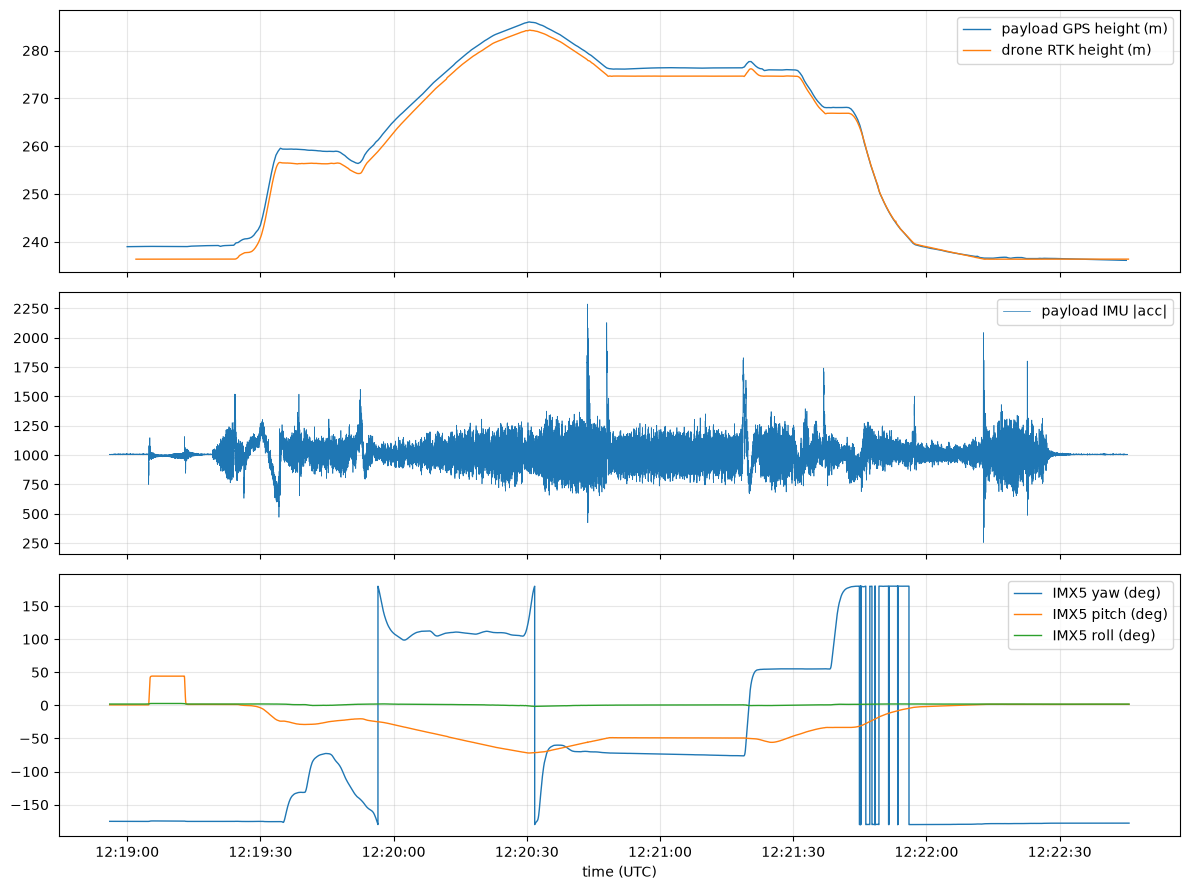

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(gps["datetime"], gps["posllh_height"], lw=1, label="payload GPS height (m)")
axes[0].plot(drone["datetime"], drone["RTK:hmsl_p"], lw=1, label="drone RTK height (m)")
acc = imu.accelerometer.data
axes[1].plot(acc["datetime"], (acc["acc_x"] ** 2 + acc["acc_y"] ** 2 + acc["acc_z"] ** 2).sqrt(), lw=0.5, label="payload IMU |acc|")
for col in ("yaw", "pitch", "roll"):
    axes[2].plot(ins["datetime"], ins[col], lw=1, label=f"IMX5 {col} (deg)")
for ax in axes:
    ax.legend(loc="upper right"); ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("time (UTC)"); plt.tight_layout(); plt.show()

## Sync

Time offset of each source against the payload GPS (`flight.sync_offsets`) and the
data resampled on a common time base (`flight.sync_data`).

In [7]:
flight.sync()
for source, off in flight.sync_offsets.items():
    corr = off.get("correlation")
    print(f"{source:14s} {off['time_offset']:+8.3f} s" + (f"  (corr {corr:.3f})" if corr is not None else ""))
print("sync_data:", {k: getattr(v, "shape", type(v).__name__) for k, v in flight.sync_data.items()})

2026-11-03 12:15:23,808 - pils.synchronizer - INFO - Set GPS payload reference with 451 samples
2026-11-03 12:15:23,808 - pils.synchronizer - INFO - Added drone GPS with 1114 samples
2026-11-03 12:15:23,808 - pils.synchronizer - INFO - Added inclinometer with 32796 samples
2026-11-03 12:15:23,809 - pils.synchronizer - INFO - Added payload sensor 'imu_barometer' with 34349 samples
2026-11-03 12:15:23,809 - pils.synchronizer - INFO - Added payload sensor 'imu_accelerometer' with 34380 samples
2026-11-03 12:15:23,810 - pils.synchronizer - INFO - Added payload sensor 'imu_gyroscope' with 34408 samples
2026-11-03 12:15:23,810 - pils.synchronizer - INFO - Added payload sensor 'imu_magnetometer' with 34252 samples
2026-11-03 12:15:23,810 - pils.synchronizer - INFO - Detecting drone GPS offset via NED correlation...
2026-11-03 12:15:23,814 - pils.synchronizer - INFO - Correlation: 1793103541.97438 1793103765.0
2026-11-03 12:15:23,817 - pils.synchronizer - INFO - Drone GPS offset: -0.373s (corr

drone_gps        -0.373 s  (corr 0.998)
camera           +0.000 s
sync_data: {'drone': (2251, 35), 'camera': (1126, 2), 'imu_barometer': (22501, 4), 'imu_accelerometer': (22501, 5), 'imu_gyroscope': (22501, 5), 'imu_magnetometer': (22501, 5), 'reference_gps': (451, 34)}


## Photogrammetry results

`photogrammetry_data`: one row per frame and telescope -- `frame`, `time` (UTC s,
synced), PnP pose (`rvec_*`, `tvec_*`, `*_corr`, `projection_error`), drone GPS
(`drone_E/N/U`), and the drone attitude seen from each telescope (`tel_name`,
`yaw`, `pitch`, `roll`, deg).

In [8]:
photo = PhotogrammetryAnalysis(flight)
print("versions:", photo.list_versions())
version = photo.get_latest_version()   # or photo.load_version("rev_YYYYMMDD_HHMMSS")
if version is None:
    print(f"No photogrammetry results in {photo.photogrammetry_dir} -- run IPA_flight/examples/")
else:
    result = version.photogrammetry_data
    print(version.version_name, result.shape)
    for k in ("camera_model", "config_file", "sync_offsets_s", "num_rows"):
        print(f"  {k}: {version.metadata.get(k)}")

2026-11-03 12:15:23,828 - pils.analyze.photogrammetry - INFO - Initialized photogrammetry analysis for flight: /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/flight_20261027_1318


versions: ['rev_20261102_162421']
rev_20261102_162421 (4290, 40)
  camera_model: alvium
  config_file: /Users/federico/Desktop/ARS/IPA_flight/config/photogrammetryConfigSony_v202610_paderno.yaml
  sync_offsets_s: {'drone': -0.3734271754045468, 'litchi': 0.0, 'camera': 0.0}
  num_rows: 4290


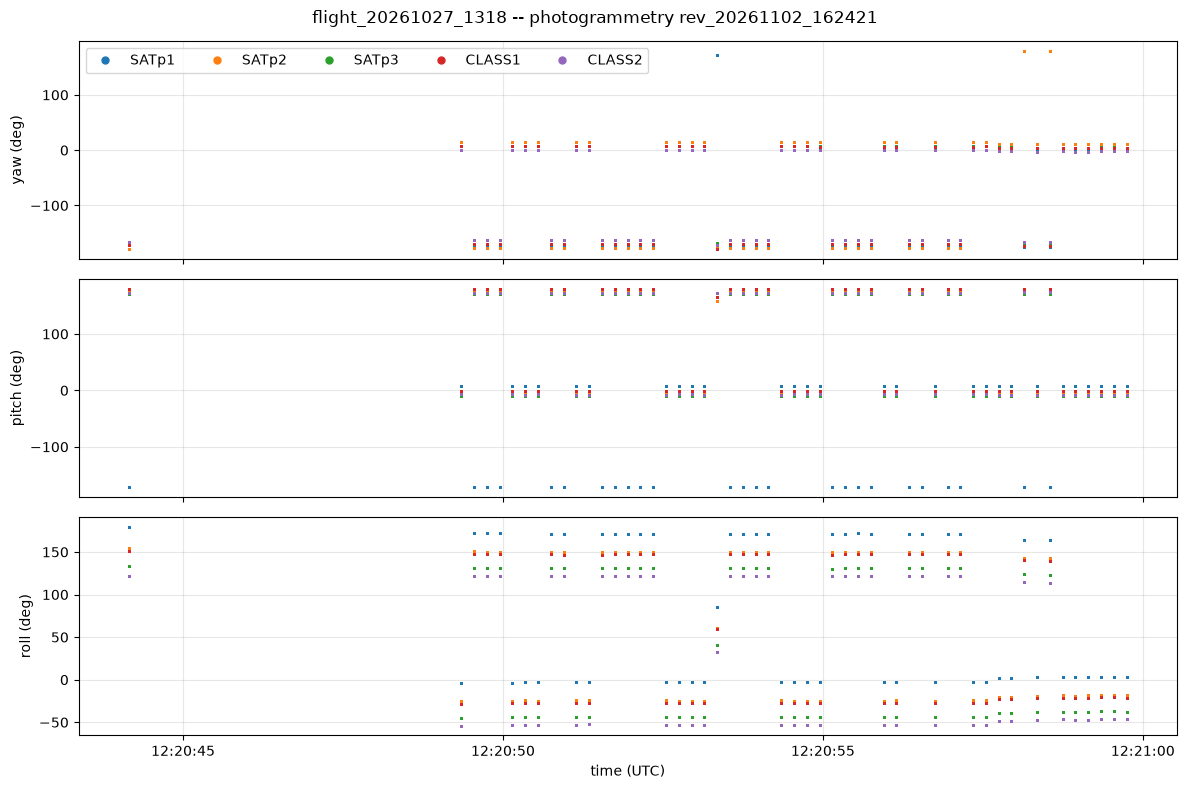

In [9]:
if version is not None:
    att = result.select(["time", "tel_name", "yaw", "pitch", "roll"]).drop_nulls()
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for (tel,), df in att.group_by("tel_name", maintain_order=True):
        t = pd.to_datetime(df["time"].to_numpy(), unit="s")
        for ax, col in zip(axes, ["yaw", "pitch", "roll"]):
            ax.plot(t, df[col], ".", ms=2, label=tel)
    for ax, col in zip(axes, ["yaw", "pitch", "roll"]):
        ax.set_ylabel(f"{col} (deg)"); ax.grid(True, alpha=0.3)
    axes[0].legend(markerscale=5, ncol=5); axes[-1].set_xlabel("time (UTC)")
    fig.suptitle(f"{FLIGHT_NAME} -- photogrammetry {version.version_name}"); plt.tight_layout(); plt.show()

## EKF results

In [10]:
ekf = EKFAnalysis(flight)   # note: creates <flight>/proc/ekf/ if missing
print("versions:", ekf.list_versions())
ekf_version = ekf.get_latest_version()
if ekf_version is None:
    print(f"No EKF results in {ekf.ekf_dir}")
else:
    print(ekf_version.version_name, ekf_version.ekf_data.shape)
    display(ekf_version.ekf_data.head())

2026-11-03 12:15:23,945 - pils.analyze.ekf - INFO - Initialized EKF analysis for flight: /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/flight_20261027_1318
2026-11-03 12:15:23,945 - pils.analyze.ekf - INFO - EKF directory: /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/flight_20261027_1318/proc/ekf


versions: []
No EKF results in /Volumes/WD/data/POLOCALC/campaigns/202610/20261027/flight_20261027_1318/proc/ekf
